## Dataset
**Link:** https://data.mendeley.com/datasets/9g668bfhy5/3

**Name:** RoseLeafSet: Real-World Leaf Image Dataset for AI-Based Agricultural Solutions

| Class | Images |
|---|---|
| Black Spot | 1288 |
| Dry Leaf | 324 |
| Healthy Leaf | 819 |
| Leaf Holes | 683 |

Processed Image : Total 3114 rose-leaf photos with the background removed (white), leaf cropped and centred, 2024×2024 JPG.


## Setup

In [11]:
import os
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


## resize every image **once** to 128×128

In [12]:
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

src_dir = 'RoseLeafSet'    # 2024x2024 background-removed photos
data_dir = 'RoseLeafSet Image_128'     # resized copies used for training

IMG_SIZE = 128                 # images are square, so 128 x 128

def resize_one(job):
    src, dst = job
    if not os.path.exists(dst):
        img = Image.open(src)
        img.draft('RGB', (IMG_SIZE * 2, IMG_SIZE * 2))   # fast JPEG decode at reduced size
        img.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR).save(dst)

jobs = []
for cls in os.listdir(src_dir):
    if cls.startswith('.'):
        continue
    os.makedirs(os.path.join(data_dir, cls), exist_ok=True)
    for f in os.listdir(os.path.join(src_dir, cls)):
        jobs.append((os.path.join(src_dir, cls, f), os.path.join(data_dir, cls, f)))

todo = [j for j in jobs if not os.path.exists(j[1])]
print(f"{len(jobs)} images, {len(todo)} still need resizing")
with ThreadPoolExecutor(max_workers=8) as pool:   # several images at once
    list(pool.map(resize_one, todo))
print("Done. Resized images are in", data_dir)

3114 images, 0 still need resizing
Done. Resized images are in RoseLeafSet Image_128


## Load ImageFolder

In [13]:
class LeafFolder(datasets.ImageFolder):
    # Same as ImageFolder, but ignores hidden folders such as .ipynb_checkpoints
    def find_classes(self, directory):
        classes = sorted(d.name for d in os.scandir(directory)
                         if d.is_dir() and not d.name.startswith('.'))
        return classes, {c: i for i, c in enumerate(classes)}

IMG_SIZE = 128
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),     # resize to model input size
    transforms.RandomHorizontalFlip(),           # flip left-right
    transforms.RandomVerticalFlip(),             # flip up-down (leaves have no fixed orientation)
    transforms.RandomRotation(20, fill=(255, 255, 255)),   # rotate ±20°, fill corners with white
    transforms.ColorJitter(brightness=0.2, contrast=0.2),  # lighting changes (keep colours - they matter for disease)
    transforms.ToTensor(),                       # convert PIL -> tensor [0,1]
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),  # 0-1
])

# data_dir = 'Processed Image'

# Two views of the SAME folder: one with augmentation (train), one clean (val/test)
full_train_view = LeafFolder(data_dir, transform=train_transform)
full_clean_view = LeafFolder(data_dir, transform=val_transform)

class_names = full_clean_view.classes
targets = np.array(full_clean_view.targets)
print("Classes:", class_names)
print("Total images:", len(full_clean_view))

Classes: ['BlackSpot', 'DryLeaf', 'HealthyLeaf', 'LeafHoles']
Total images: 3114


## How many images per class?

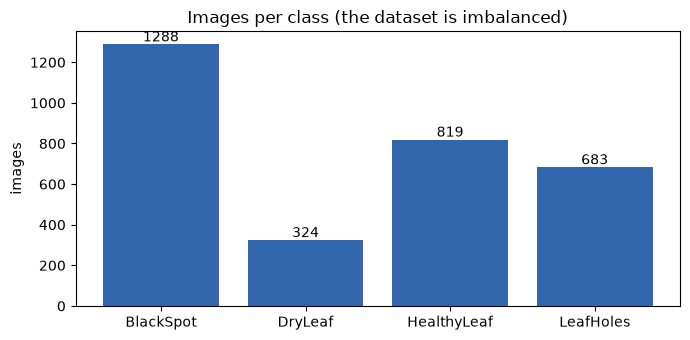

In [14]:
counts = np.bincount(targets, minlength=len(class_names))

plt.figure(figsize=(7, 3.5))
plt.bar(class_names, counts, color="#3266ad")
for i, c in enumerate(counts):
    plt.text(i, c + 15, str(c), ha='center', fontsize=10)
plt.ylabel("images")
plt.title("Images per class (the dataset is imbalanced)")
plt.tight_layout()
plt.show()

## Train / validation / test split
- **Train (70%)** - **Validation (15%)** - **Test (15%)**

In [15]:
from sklearn.model_selection import train_test_split

all_idx = np.arange(len(targets))

# 70% train, 30% temp  ->  temp split in half: 15% val, 15% test
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=targets, random_state=42)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=42)

train_data = Subset(full_train_view, train_idx)   # augmented
val_data   = Subset(full_clean_view, val_idx)     # clean
test_data  = Subset(full_clean_view, test_idx)    # clean

print(f"Train:{len(train_data)}")
print(f"Val:{len(val_data)}")
print(f"Test:{len(test_data)}")

Train:2179
Val:467
Test:468


## Look at a few images

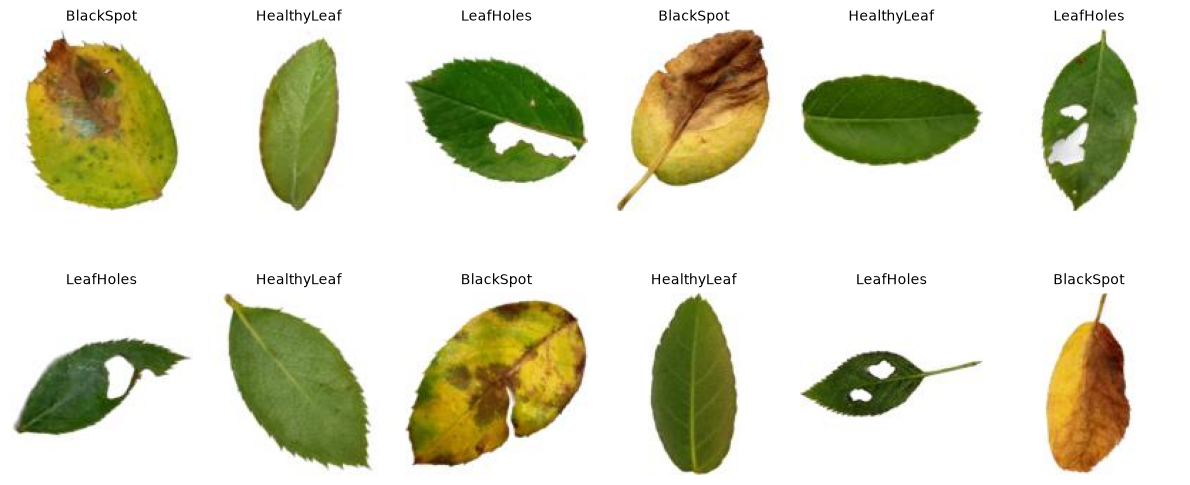

In [16]:
rng = np.random.default_rng(1)
show = rng.choice(len(val_data), 12, replace=False)

plt.figure(figsize=(12, 6))
for k, i in enumerate(show):
    img, label = val_data[i]
    plt.subplot(2, 6, k + 1)
    plt.imshow(img.permute(1, 2, 0))   # [C,H,W] -> [H,W,C]
    plt.title(class_names[label], fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Hyperparameters and DataLoaders

In [17]:
#important HyperParameters
batch_size = 32
learning_rate = 0.001
minimum_learning_rate = 1e-4
epochs = 100
num_classes = len(class_names)   # 4

In [18]:
# num_workers=0 is the safe choice for Jupyter on Windows
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_data,   batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_data,  batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

## Build the CNN

In [19]:
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR

class CNNModel(nn.Module):
    def __init__(self, num_classes=4):
        super(CNNModel, self).__init__()

        # Convolutional layers
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),
        )

        # Fully connected layers/Classification Head/ANN
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.7),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

#1. Get the Model
model = CNNModel(num_classes=num_classes).to(device)
# 2. Define optimizer
optimizer = Adam(model.parameters(), lr=learning_rate)
# 3. Define LR scheduler
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate)
# 4. Define loss function
criterion = nn.CrossEntropyLoss()

from torchsummary import summary
summary(model, input_size=(3, IMG_SIZE, IMG_SIZE), device=device);

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1        [-1, 128, 128, 128]           3,584
         MaxPool2d-2          [-1, 128, 64, 64]               0
              ReLU-3          [-1, 128, 64, 64]               0
            Conv2d-4          [-1, 128, 64, 64]         147,584
         MaxPool2d-5          [-1, 128, 32, 32]               0
              ReLU-6          [-1, 128, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]         147,584
         MaxPool2d-8          [-1, 128, 16, 16]               0
              ReLU-9          [-1, 128, 16, 16]               0
           Conv2d-10          [-1, 128, 16, 16]         147,584
        MaxPool2d-11            [-1, 128, 8, 8]               0
             ReLU-12            [-1, 128, 8, 8]               0
          Flatten-13                 [-1, 8192]               0
           Linear-14                  [

## Train

In [20]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()        # gradient calculation
        optimizer.step()       # weight update
        optimizer.zero_grad()

        total_loss += loss.item()

        # compute accuracy
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(loader)
    train_acc = correct / total

    return train_loss, train_acc

def validate_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / len(loader)
    val_acc = correct / total

    return val_loss, val_acc

In [21]:
import copy

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

best_val_acc = 0.0
best_acc_epoch = 0
best_weights = None

best_val_loss = float('inf')   # lowest validation loss seen so far
best_loss_epoch = 0

for epoch in range(epochs):
    print(f"----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_acc_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_loss_epoch = epoch + 1

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

print("\n==================== Summary ====================")
print(f"Best validation accuracy : {best_val_acc:.4f} (epoch {best_acc_epoch})")
print(f"Best validation loss     : {best_val_loss:.4f} (epoch {best_loss_epoch})")
print(f"Best training loss       : {min(train_losses):.4f} (epoch {int(np.argmin(train_losses)) + 1})")
model.load_state_dict(best_weights)          # use the best epoch from now on
torch.save(best_weights, 'cnn_best.pth')

----------------------------------------------------
Epoch 1/100, LR: 0.001
Train Loss: 1.2935 | Train Acc: 0.3933
Val Loss: 1.1336 | Val Acc: 0.4304
----------------------------------------------------
Epoch 2/100, LR: 0.000999778
Train Loss: 0.9181 | Train Acc: 0.5801
Val Loss: 0.7017 | Val Acc: 0.6916
----------------------------------------------------
Epoch 3/100, LR: 0.000999112
Train Loss: 0.7753 | Train Acc: 0.6590
Val Loss: 0.6932 | Val Acc: 0.6660
----------------------------------------------------
Epoch 4/100, LR: 0.000998003
Train Loss: 0.7133 | Train Acc: 0.6971
Val Loss: 0.5304 | Val Acc: 0.8030
----------------------------------------------------
Epoch 5/100, LR: 0.000996452
Train Loss: 0.5385 | Train Acc: 0.8086
Val Loss: 0.3576 | Val Acc: 0.8758
----------------------------------------------------
Epoch 6/100, LR: 0.00099446
Train Loss: 0.4367 | Train Acc: 0.8637
Val Loss: 0.3365 | Val Acc: 0.8972
----------------------------------------------------
Epoch 7/100, LR: 0

## Loss and accuracy curves

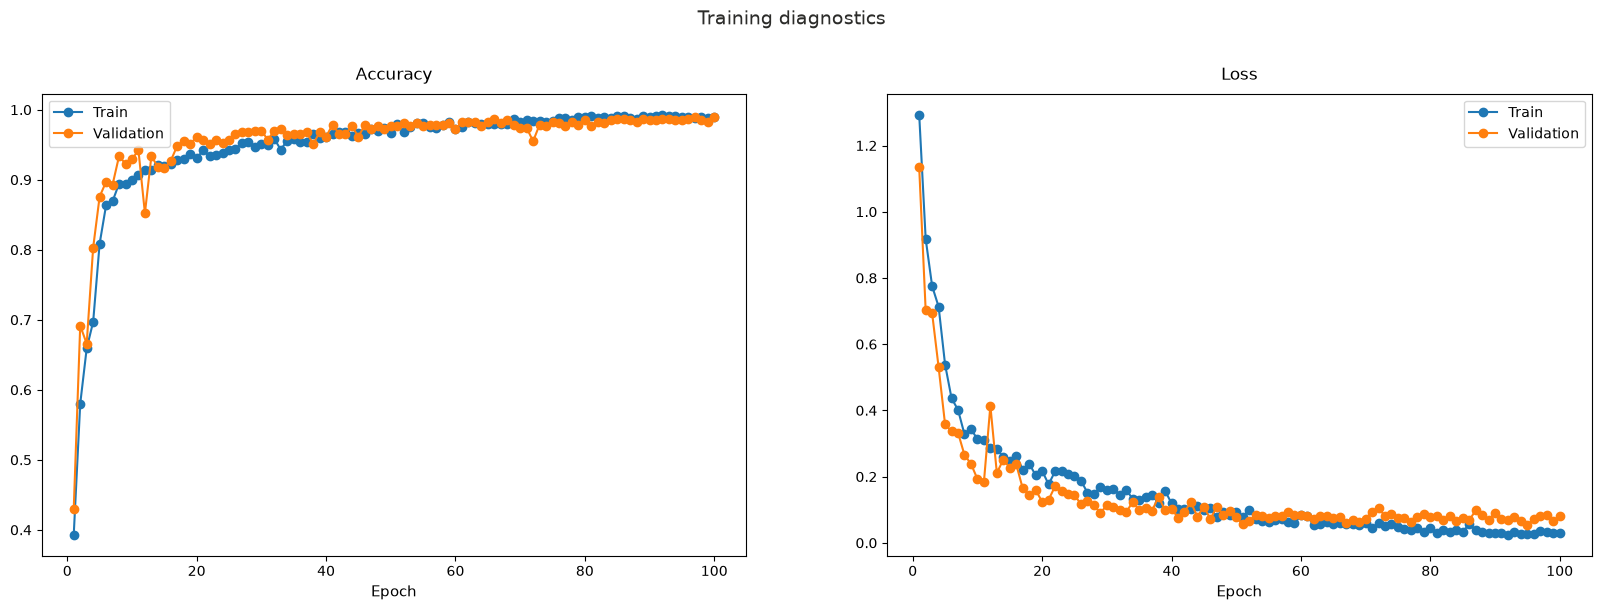

In [22]:
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker

epochs_number = np.arange(1, epochs + 1)
fig = plt.figure(figsize=(20, 6))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2)

# ── Accuracy ──────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, "o-", label="Train")
ax1.plot(epochs_number, val_accuracies, "o-", label="Validation")
ax1.set_xlabel("Epoch", color="#000000", fontsize=11)
ax1.set_title("Accuracy", fontsize=12, color="#000000", pad=10)
ax1.legend()


# ── Loss ──────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, "o-", label="Train")
ax2.plot(epochs_number, val_losses, "o-", label="Validation")
ax2.set_xlabel("Epoch", color="#000000", fontsize=11)
ax2.set_title("Loss", fontsize=12, color="#000000", pad=10)
ax2.legend()

fig.suptitle("Training diagnostics", fontsize=14, color="#2c2c2a", y=1.02)
plt.savefig("training_curves.png", bbox_inches="tight", dpi=150)
plt.show()

## Final evaluation on the test set

In [23]:
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
misclassified = []
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        # Save all predictions and labels for confusion matrix
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        # Store misclassified images
        for img, true, pred in zip(images, labels, preds):
            if true != pred:
                misclassified.append((img.cpu(), true.item(), pred.item()))

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)
test_acc = (all_preds == all_labels).mean()
print(f"Test accuracy: {test_acc:.4f}")
print(f"Total misclassified samples: {len(misclassified)} / {len(all_labels)}\n")

# Per-class precision, recall, f1
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

Test accuracy: 0.9744
Total misclassified samples: 12 / 468

              precision    recall  f1-score   support

   BlackSpot     0.9844    0.9742    0.9793       194
     DryLeaf     0.9565    0.9167    0.9362        48
 HealthyLeaf     0.9609    1.0000    0.9801       123
   LeafHoles     0.9804    0.9709    0.9756       103

    accuracy                         0.9744       468
   macro avg     0.9706    0.9654    0.9678       468
weighted avg     0.9745    0.9744    0.9743       468



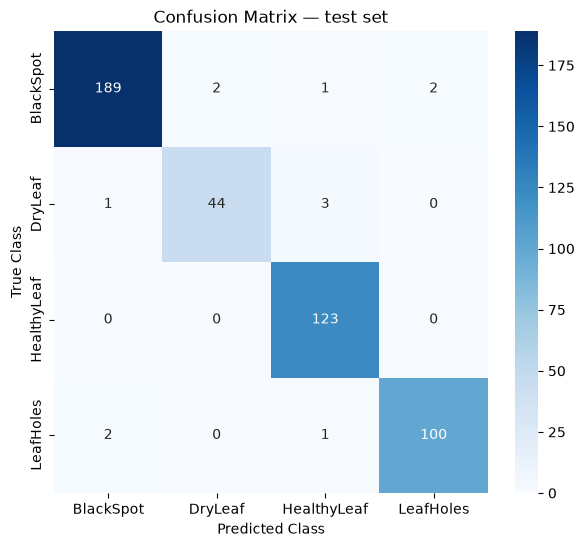

In [24]:
#Confusion Matrix
import seaborn as sns
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix — test set")
plt.show()

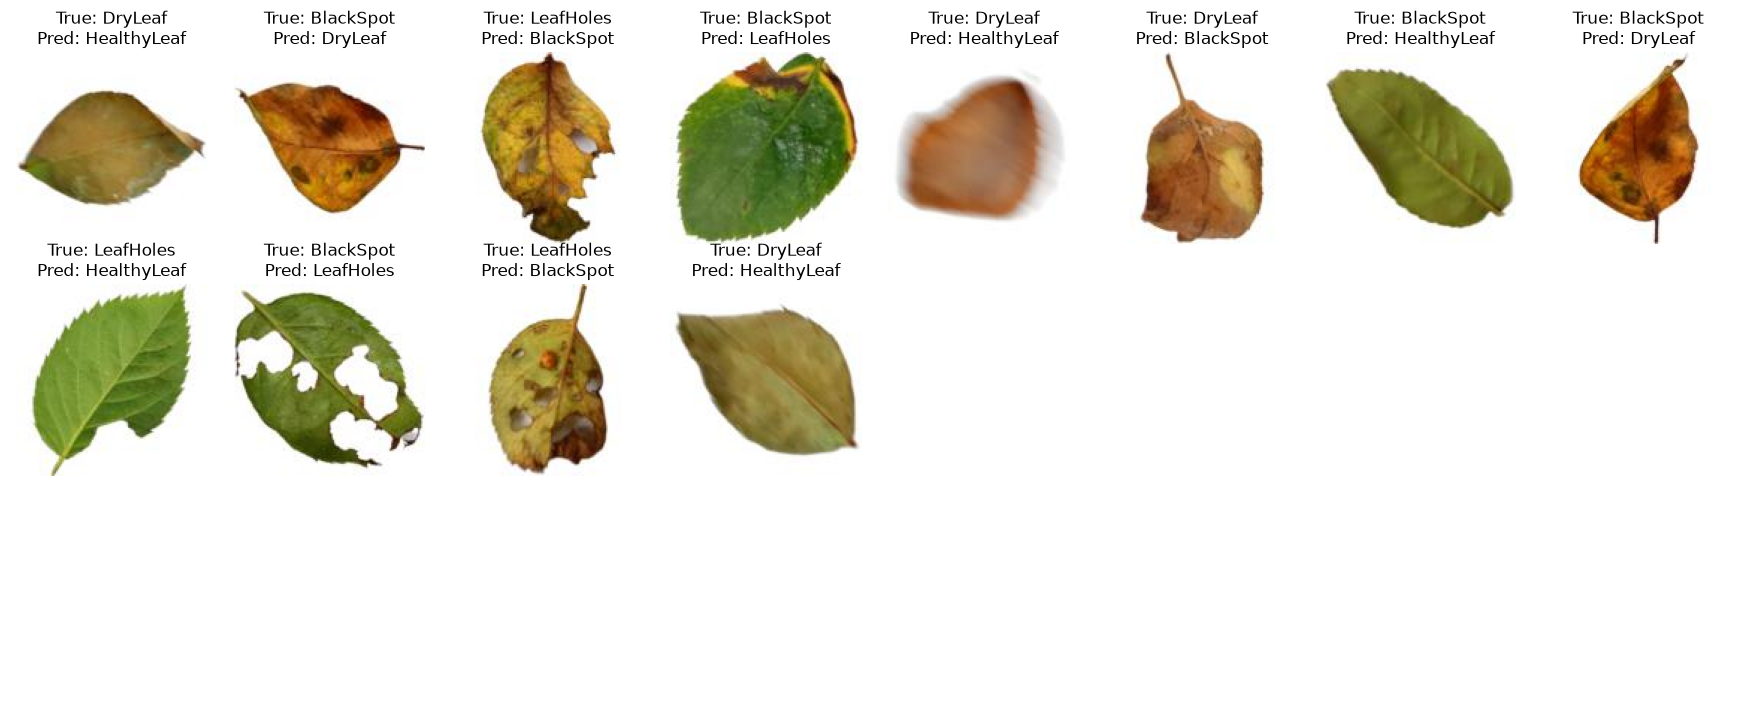

In [25]:
# Misclassified test images
num_rows = 3
num_cols = 8
num_to_show = min(num_rows * num_cols, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2.2, num_rows * 2.4))
axes = axes.flatten()

for idx in range(num_to_show):
    img, true, pred = misclassified[idx]
    axes[idx].imshow(img.permute(1, 2, 0))   # CxHxW -> HxWxC
    axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}")
    axes[idx].axis('off')

for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()